# Characterize Response in Opsin-Positive Neurons

This notebook demonstrates how to analyze patch clamp recordings from opsin-expressing neurons,
including cell type classification based on electrophysiological properties and spatial mapping
of responses to focal optogenetic stimulation.

Key steps include:
1. Loading and organizing in vitro experimental data
2. Extracting and analyzing IV curve properties
3. Classifying cell types (FSI vs RS) based on ephys properties  
4. Analyzing responses to focal optogenetic stimulation
5. Comparing responses to static vs dynamic stimulation sequences

Methods rely on `xarray` for multidimensional data handling and `mimo_pack` for standardized analysis workflows.

## Import Libraries

Standard scientific Python libraries (`numpy`, `pandas`, `xarray`, `matplotlib`) are imported alongside `mimo_pack` modules for file I/O, preprocessing, analysis, and plotting. Widget classes handle the interactive classification steps. All data-type constants (`DIM_TIME`, `DIM_EPOCH`) are imported from `mimo_pack.consts` rather than hardcoded as strings.


In [ ]:

# Environment: conda activate mimo_env2  (see environment.yml)

import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

from mimo_pack.consts import DIM_TIME, DIM_EPOCH
from mimo_pack.fileio.abf import load_abf, load_abf_settings

from mimo_pack.fileio.image import load_images
from mimo_pack.fileio.invitro import invitro_files_df, summarize_invitro_protocols, extract_protocol_files
from mimo_pack.plot.dataframe import PlotGrid
from mimo_pack.plot.timeseries import stacked_lines
from mimo_pack.plot.invitro import focal_stim_map, stim_pattern_map
from mimo_pack.preprocess.invitro import (
    format_ivic, format_focal_stimulation,
    format_blue_tonic_led, get_holding_potential, remove_current_offset,
)
from mimo_pack.analysis.invitro_ephys_props import (
    extract_iv_properties, fit_opsin_response, opsin_iv_conductance,
)
from mimo_pack.util.xarray import (
    concat_by_attr, select_mode, select_by_coord,
    save_dataarray_df, explode_xarray,
)
from mimo_pack.util.dataframe import apply_to_columns, pipe_columns, pipe_groupby_reduce
from mimo_pack.widgets.cell_class_invitro import CellClassificationWidget
from mimo_pack.widgets.opsin import OpsinClassificationWidget
from mimo_pack.widgets.cell_selector import CellSelectorWidget


## Data Paths

**Edit this cell before running the notebook.** Set `invitro_path` to the root directory containing the in vitro recordings, and `imgs_path` to the folder of optogenetic stimulation pattern images. Processed outputs (NetCDF files) are written to `save_dir`. Figures are written to `figures_dir`, which is automatically named after this notebook.


In [ ]:
from pathlib import Path

# ── Configure these paths before running ────────────────────────────────────

# Path to in vitro data directory
invitro_path = os.path.join('D:', 'BetaGamma', 'project', 'invitro', 'v1')

# Path to optogenetic stimulation pattern images
imgs_path = os.path.join('D:', 'BetaGamma', 'project', 'invitro', 'optopatterns', 'single_squares')

# Output directory for processed data
save_dir = os.path.join(invitro_path, 'processed')

# Figures directory — named after this notebook with _figures suffix
try:
    _nb_stem = Path(__vsc_ipynb_file__).stem
except NameError:
    _nb_stem = 'CharacterizeOpsinCells'
figures_dir = os.path.join(save_dir, f'{_nb_stem}_figures')


## Experiment Parameters

Dataset-specific constants that control the entire pipeline. `IVIC_PROTOCOLS` and `TONIC_PROTOCOLS` are the ABF protocol names used to identify IV-curve and tonic LED recordings, respectively. `FOCAL_PROTO_NAMES` lists focal stimulation protocols in priority order (first match wins per cell). `patt_px_per_um` converts pattern image pixels to micrometers based on the microscope calibration. The V-Clamp constants (`VC_FIT_ATTRS`, `VC_COND_KEYS`, `EXPECTED_VC_CHANNELS`) define the expected recording structure and the attributes used to aggregate fits across holding potentials.


In [3]:
# Expected protocol names
IVIC_PROTOCOLS = ['Left_IVIC']

# Tonic LED protocol
TONIC_PROTOCOLS = ['Left_BlueLED_Tonic_IC']

# Focal stimulation protocol names (tried in order; first match wins)
FOCAL_PROTO_NAMES = [
    'Left_StaticSeqLong_SingleCircle',
]

# Calibration: 45 image px = 16 pattern px; microscope = 8.5 image px/μm
# → pattern pixels per μm = (16/45) × 8.5
patt_px_per_um = 16 / 45 * 8.5

# ── V-Clamp IV fit: attributes used as concat coordinates ───────────
VC_FIT_ATTRS = ['v_hold', 'led_power', 'peak_amp', 'A_sust',
                'A_transient', 'tau_inact_ms', 'baseline']

# Column names for chord-conductance output
VC_COND_KEYS = ['g_peak_nS', 'g_sust_nS', 'E_rev_peak_mV', 'E_rev_sust_mV',
                'r2_peak', 'r2_sust', 'n_points']

# Expected V-Clamp channel names (raise an error if a recording differs)
EXPECTED_VC_CHANNELS = ['Left 1', 'I', 'IN 5']


## Notebook Helpers

Small helper functions used in the pipeline cells below. Defined here so the pipeline cells stay concise.

In [ ]:
# ── V-Clamp helpers ──────────────────────────────────────────────────

def _load_and_prep(fpath):
    """Load ABF, format, validate channels, extract and attach v_hold."""
    rec = load_abf(fpath)
    rec_fmt = format_blue_tonic_led(rec)
    if rec_fmt.ch_names.values.tolist() != EXPECTED_VC_CHANNELS:
        raise ValueError(
            f"Unexpected channels {rec_fmt.ch_names.values.tolist()}; "
            f"expected {EXPECTED_VC_CHANNELS}"
        )
    hold = get_holding_potential(rec_fmt)
    v_hold = float(hold[list(hold.data_vars)[0]].median())
    rec_fmt.attrs['v_hold'] = v_hold
    return rec_fmt

def _fit_with_vhold(rec_clean):
    """Fit opsin response and carry v_hold from input attrs."""
    fit = fit_opsin_response(rec_clean, A_sust_fixed=True)
    fit.attrs['v_hold'] = rec_clean.attrs['v_hold']
    return fit

def plot_photocurrent(row, ax):
    """Plot data trace and fitted curve for a single V-Clamp recording."""
    rec_trace = row['rec_pA']
    fit_trace = row['fit']
    led_dur = float(rec_trace.attrs.get('led_dur', 0.05))
    ax.plot(rec_trace[DIM_TIME].values, rec_trace.values,
            color='gray', alpha=0.7, lw=1.2, label='Data')
    ax.plot(fit_trace[DIM_TIME].values, fit_trace.values,
            color='C1', lw=2, label='Fit')
    ax.axvline(0, color='steelblue', lw=0.8, ls='--', label='LED on/off')
    ax.axvline(led_dur, color='steelblue', lw=0.8, ls='--')
    ax.set_xlim(-0.01, led_dur + 0.05)

def _make_plot_iv_curve(vc_cond):
    """Return a plot function closed over the conductance DataFrame."""
    def _plot_iv_curve(row, ax):
        """Plot I-V curve (peak and sustained) for one cell."""
        fit = row['fit']
        v = fit['v_hold'].values
        ip = fit['peak_amp'].values
        ia = fit['A_sust'].values
        order = np.argsort(v)
        ax.plot(v[order], ip[order], 'o-', label='Peak')
        ax.plot(v[order], ia[order], 's-', label='Sustained')
        ax.axhline(0, color='k', lw=0.5, ls='--')
        cond = vc_cond.loc[row.name]
        ax.set_title(f"Cell {row.name}\ng_peak={cond['g_peak_nS']:.1f} nS  "
                     f"g_sust={cond['g_sust_nS']:.1f} nS", fontsize=9)
    return _plot_iv_curve

def _calc_conductance(fit):
    d = opsin_iv_conductance(fit['v_hold'].values, fit['peak_amp'].values, fit['A_sust'].values)
    return tuple(d[k] for k in VC_COND_KEYS)

# ── I-Clamp helpers ─────────────────────────────────────────────────

def _concat_epochs(recs):
    """Concatenate recordings along the epoch dimension."""
    rec_cat = xr.concat(recs, dim=DIM_EPOCH) if len(recs) > 1 else recs[0]
    rec_cat.attrs.update(recs[0].attrs)
    return rec_cat

def _prep_ic_voltage(rec):
    """Select mV channel and window around LED pulse."""
    rec_v = select_by_coord(rec, 'ch_units', 'mV').isel(channel=0)
    led_dur = float(rec.attrs.get('led_dur', 0.5))
    return rec_v.sel({DIM_TIME: slice(-0.05, led_dur + 0.1)})

def _plot_ic_tonic(row, ax):
    """Plot stacked voltage traces for I-Clamp tonic LED response."""
    rec_v = row['rec_v']
    led_dur = float(row['rec'].attrs.get('led_dur', 0.5))
    stacked_lines(rec_v, time_dim=DIM_TIME, chan_dim=DIM_EPOCH, ax=ax)
    n_epochs = rec_v.sizes[DIM_EPOCH]
    ax.set_title(f"{row['subject']}_{row['slice']}_{row['cell']}  —  {n_epochs} epochs",
                 fontweight='bold')

# ── Focal stimulation helpers ───────────────────────────────────────

def _load_and_format_focal(fpath, patterns, n_patterns, patt_px_per_um):
    """Load ABF, skip files with too few epochs, then format.

    Parameters
    ----------
    fpath : str
        Path to the ABF file.
    patterns : array-like
        Loaded stimulation pattern images (from load_images).
    n_patterns : int
        Minimum number of expected epochs (len(patterns)).
    patt_px_per_um : float
        Pattern pixels per micrometer calibration factor.
    """
    rec = load_abf(fpath)
    if rec.sizes[DIM_EPOCH] <= n_patterns:
        raise ValueError(f"n_epochs ({rec.sizes[DIM_EPOCH]}) <= n_patterns ({n_patterns})")
    return format_focal_stimulation(rec, patterns, px_per_um=patt_px_per_um)


## Load and Organize Experimental Files

Use `invitro_files_df()` to scan the directory and create a DataFrame of all cells with their associated protocols.

In [5]:
cells = invitro_files_df(invitro_path, required_ext=['.abf', '.tif'])

## Select Cells by Protocol and Clamp Mode

Use `CellSelectorWidget` to interactively filter the cells DataFrame to only the cells that have recordings for the desired protocol(s) and clamp mode(s).

1. Check any combination of (protocol, clamp mode) rows
2. Choose **AND** (cells must have all selected) or **OR** (cells must have any selected)
3. Click **Apply Filter** — the filtered DataFrame is available as `cell_selector.cells_df`


In [ ]:
cell_selector = CellSelectorWidget()
cell_selector.set_dataframes({'cells': cells})
cell_selector.display()


In [8]:
# Retrieve the filtered DataFrame from the widget.
# Run the cell above first and click "Apply Filter" before proceeding.
selected_cells = cell_selector.cells_df
print(f"{len(selected_cells)} / {len(cells)} cells selected")
selected_cells


3 / 20 cells selected


ext,subject,slice,cell,.abf,.nc,.tif,.txt,protocols
3,DH46,Slice1,Cell2,[D:BetaGamma\project\invitro\v1\DH46\Slice1\Ce...,NaN,[D:BetaGamma\project\invitro\v1\DH46\Slice1\Ce...,[D:BetaGamma\project\invitro\v1\DH46\Slice1\Ce...,{'Left_IVIC': [{'file': 'D:BetaGamma\project\i...
13,DH55,Slice1,Cell3,[D:BetaGamma\project\invitro\v1\DH55\Slice1\Ce...,NaN,[D:BetaGamma\project\invitro\v1\DH55\Slice1\Ce...,NaN,{'Left_IVIC': [{'file': 'D:BetaGamma\project\i...
15,DH56,Slice1,Cell1,[D:BetaGamma\project\invitro\v1\DH56\Slice1\Ce...,NaN,[D:BetaGamma\project\invitro\v1\DH56\Slice1\Ce...,NaN,{'Left_IVIC': [{'file': 'D:BetaGamma\project\i...


## Classify Cells by Electrophysiological Properties

Use the `CellClassificationWidget` to interactively:

1. Select the cells DataFrame and IV-clamp protocol name (default `Left_IVIC`)
2. Run the extraction loop — each cell's IVIC recording is loaded, formatted with
   `format_ivic`, and processed with `extract_iv_properties`
3. Adjust classification thresholds and classify cells:
   - **LTS** (checked first, takes priority): sag ratio ≤ threshold *and* max rebound APs ≥ threshold
   - **FSI**: AP half-width ≤, membrane τ ≤, max firing rate ≥ (all three must agree)
   - **RS**: all three FSI criteria oppose
   - **Unknown**: mixed FSI/RS votes, or LTS criteria not met
4. Inspect the scatter plot of any two parameters with decision boundary lines
5. Click a row in the parameter table to view that cell's stacked IV-curve traces

After running, access results via `cell_class_widget.cells_df` (includes `'class'`
column) and `cell_class_widget.props_df` (per-cell extracted properties).


In [ ]:
cell_class_widget = CellClassificationWidget()
cell_class_widget.set_dataframes({'cells': selected_cells})
cell_class_widget.display()


In [10]:
# Retrieve widget results before continuing.
# Run the widget above, classify all cells, then execute this cell.
cells_with_class = cell_class_widget.cells_df   # includes 'class' column
ephys_props_df   = cell_class_widget.props_df   # per-cell extracted properties
print(f"Cell classifications:\n{cells_with_class['class'].value_counts().to_string()}")


Cell classifications:
class
Unknown    1
LTS        1
RS         1


## Analyze Blue Tonic LED Responses (Opsin Characterization)

Use the `OpsinClassificationWidget` to interactively:

1. Select the cells DataFrame and LED protocol
2. Configure LED detection parameters (channel names, threshold, onset fallback, etc.)
3. Run the fitting loop — each cell's tonic LED recording is loaded, formatted with
   `format_blue_tonic_led`, and fit with `fit_opsin_response`
4. Inspect per-cell fits by clicking rows in the parameter table
5. Classify opsin-positive cells using adjustable thresholds (updates automatically)
6. View a scatter plot of any two fit parameters with decision boundaries

After running the widget, access results programmatically via
`opsin_widget.led_params_df` and `opsin_widget.cells_df`.


In [ ]:
opsin_widget = OpsinClassificationWidget()
opsin_widget.set_dataframes({'cells': cells_with_class})
opsin_widget.display()


In [12]:
# Retrieve widget results before continuing.
# Run the widget above, classify opsin+ cells, then execute this cell.
cells = opsin_widget.cells_df   # original cells DataFrame, now with 'opsin_class' column
print(f"Opsin classifications:\n{cells['opsin_class'].value_counts().to_string()}")


Opsin classifications:
opsin_class
opsin+    3


## Filter to Opsin-Positive Cells

The `OpsinClassificationWidget` annotates `cells` with an `'opsin_class'` column. Here, a Boolean filter selects only the rows where `opsin_class == 'opsin+'`. The original `cells` DataFrame is kept intact for reference; all downstream analyses operate on `opsin_cells`.



In [13]:
if 'opsin_class' not in cells.columns:
    raise RuntimeError(
        "'opsin_class' column missing. "
        "Run the OpsinClassificationWidget above and execute its checkpoint cell first."
    )

opsin_cells = cells[cells['opsin_class'] == 'opsin+']
print(f"{len(opsin_cells)} / {len(cells)} cells classified as opsin+")


3 / 3 cells classified as opsin+


## Voltage-Clamp Characterization of Opsin-Positive Cells to Tonic Light Pulses

Opsin-positive cells are voltage-clamped at a series of holding potentials and presented with a sustained blue LED pulse. The resulting photocurrent waveform consists of a transient peak followed by a sustained plateau, reflecting opsin activation and inactivation kinetics. By repeating this across multiple holding potentials, an I-V relationship is constructed from which the peak and sustained chord conductances, and the reversal potential, can be estimated.


### Identify V-Clamp Files and Load Data Summary

`extract_protocol_files` scans `opsin_cells` and returns a row-per-file DataFrame restricted to the tonic LED protocol in V-Clamp mode. The summary printout shows how many opsin-positive cells have qualifying recordings and how many files each cell contributed.


In [14]:
vc_files_df = extract_protocol_files(opsin_cells, TONIC_PROTOCOLS, clamp_mode='V-Clamp')

n_cells = vc_files_df['cell_idx'].nunique()
print(f"{n_cells} / {len(opsin_cells)} opsin-positive cells have V-Clamp recordings\n")
print("Protocols with V-Clamp files:")
print(vc_files_df.groupby('protocol')['fpath'].count()
      .rename('n_files').to_frame())
print()
vc_files_df.groupby('cell_idx')[['subject', 'slice', 'cell', 'protocol']].first().assign(
    n_files=vc_files_df.groupby('cell_idx')['fpath'].count()
)

3 / 3 opsin-positive cells have V-Clamp recordings

Protocols with V-Clamp files:
                       n_files
protocol                      
Left_BlueLED_Tonic_IC       12



,subject,slice,cell,protocol,n_files
cell_idx,,,,,
3,DH46,Slice1,Cell2,Left_BlueLED_Tonic_IC,4
13,DH55,Slice1,Cell3,Left_BlueLED_Tonic_IC,4
15,DH56,Slice1,Cell1,Left_BlueLED_Tonic_IC,4


### Load, Fit, and Aggregate V-Clamp Recordings

Each file is processed through a branched pipeline using `pipe_columns`:

1. **Load & format** (`_load_and_prep`) — reads the ABF, applies `format_blue_tonic_led`, validates channel names, and attaches the median holding potential as `v_hold` in `.attrs`.
2. **Offset removal** (`remove_current_offset`) — subtracts the pre-stimulus baseline current from each epoch.
3. **Opsin fit** (`_fit_with_vhold`) — fits the double-exponential + sustained photocurrent model via `fit_opsin_response`; carries `v_hold` forward.
4. **Epoch mean** — averages cleaned traces across epochs for display.

Files that fail any step are dropped (`dropna`). Per-file results are then grouped by `cell_idx` and concatenated across holding potentials with `concat_by_attr`, producing one row per cell with a 3-D DataArray (time × channel × v_hold). `select_mode` retains only epochs from the most common LED power level, discarding any trials recorded at a different intensity.


In [15]:
# Pipeline: load → clean → fit; rec_mean branches from rec_clean
vc_files_df = pipe_columns(vc_files_df, [
    ['fpath',     _load_and_prep,          'rec_fmt'],
    ['rec_fmt',   remove_current_offset,   'rec_clean'],
    ['rec_clean', _fit_with_vhold,         'fit'],
    ['rec_clean', lambda da: da.mean(dim=DIM_EPOCH, keep_attrs=True), 'rec_mean'],
], errors='warn')

# Drop rows that failed (bad channels, loading errors, etc.)
vc_files_df = vc_files_df.dropna(subset=['fit'])

# Group by cell and concat across holding potentials
vc_fits_df = pipe_groupby_reduce(vc_files_df, 'cell_idx', [
    ['fit',      lambda das: concat_by_attr(das, attr=VC_FIT_ATTRS, dim='v_hold'),              'fit'],
    ['rec_mean', lambda das: concat_by_attr(das, attr=['v_hold', 'led_power'], dim='v_hold'), 'rec'],
])

# Keep only epochs recorded at the most common LED power level (handles inconsistent recordings)
vc_fits_df = apply_to_columns(vc_fits_df, 'rec', select_mode, 'led_power')
vc_fits_df = apply_to_columns(vc_fits_df, 'fit', select_mode, 'led_power')

# Print summary — read v_hold directly from fit coordinates
print(f"Loaded I-V data for {len(vc_fits_df)} / {vc_files_df['cell_idx'].nunique()} cells")
for cell_idx, r in vc_fits_df.iterrows():
    vholds = sorted(r['fit']['v_hold'].values)
    print(f"  Cell {cell_idx}: {len(vholds)} holding levels — {[f'{v:.0f}' for v in vholds]} mV")


C:\Users\dbh60\Documents\mimo\mimo2\mimo_pack\util\dataframe.py:59: UserWarning: Row 0, step producing ['rec_fmt']: Unexpected channels ['Left 1', 'I', 'BlueLED']; expected ['Left 1', 'I', 'IN 5']
  warnings.warn(f"Row {idx}{label}: {exc}")


Loaded I-V data for 3 / 3 cells
  Cell 3: 2 holding levels — ['-28', '-18'] mV
  Cell 13: 4 holding levels — ['-61', '-52', '-51', '-31'] mV
  Cell 15: 3 holding levels — ['-78', '-58', '-28'] mV


### Plot Photocurrent Traces with Fitted Curves

The aggregated DataArray is exploded across the `v_hold` dimension so each cell × holding-potential combination becomes a separate row. `PlotGrid` arranges panels with one column per holding potential and one figure per cell. Each panel overlays the epoch-mean recorded current (gray) with the double-exponential fit (orange) and marks the LED on/off times. Files are saved to `figures_dir`.


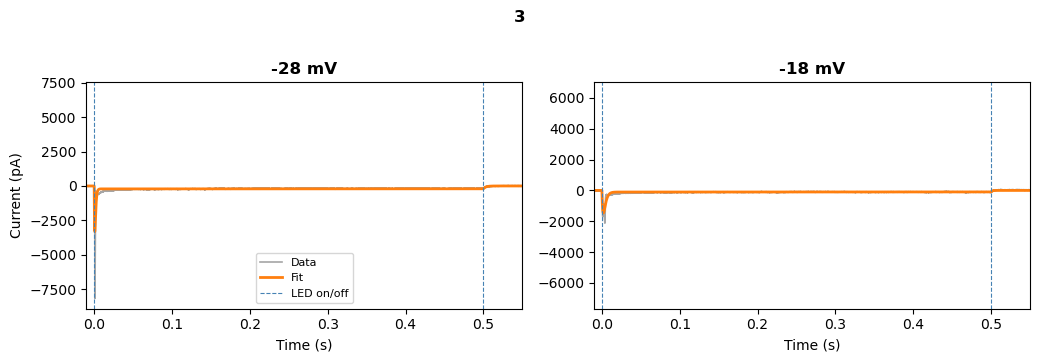

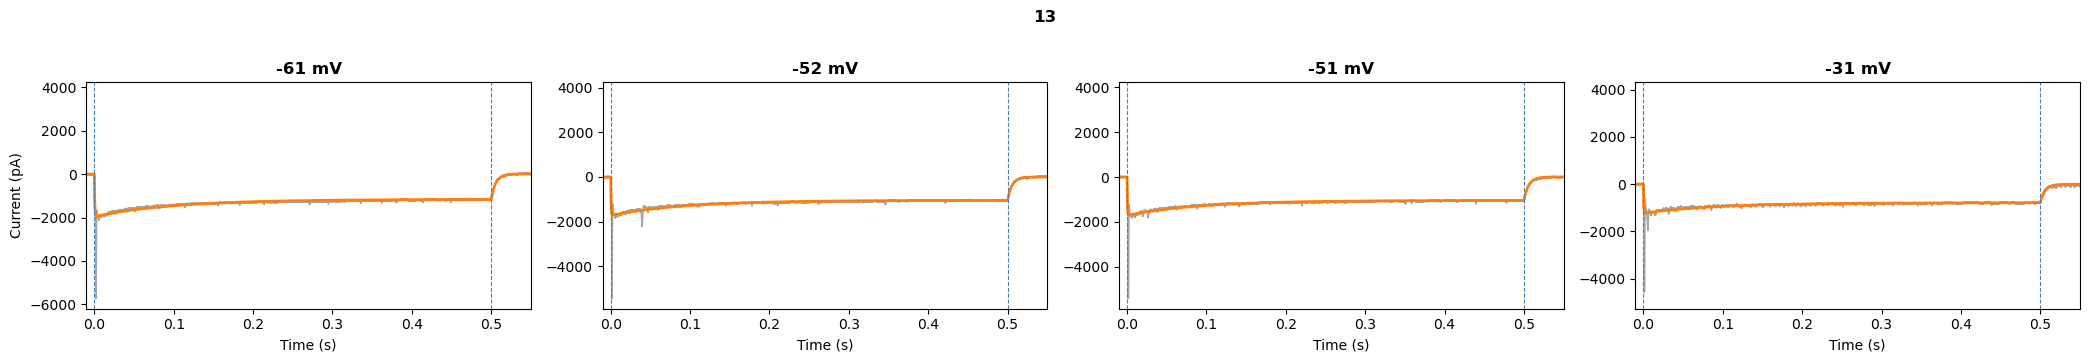

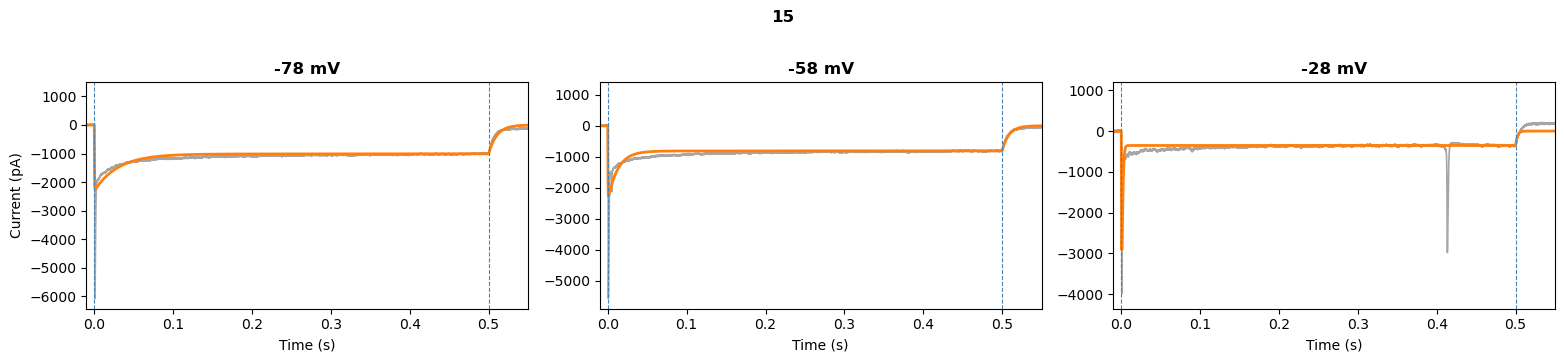

In [ ]:
# Explode v_hold dimension → one row per cell × holding potential
vc_plot_df = explode_xarray(
    vc_fits_df.reset_index(), col=['rec', 'fit'], dim='v_hold')

# Pre-select the pA (current) channel for each exploded row
vc_plot_df['rec_pA'] = [
    select_by_coord(r, 'ch_units', 'pA').isel(channel=0)
    for r in vc_plot_df['rec']
]

g = (PlotGrid(vc_plot_df, fig='cell_idx', col='v_hold',
              title_fn=lambda r: f"{r['v_hold']:.0f} mV")
     .map(plot_photocurrent)
     .set_axis_labels('Time (s)', 'Current (pA)')
     .add_legend()
     .tight_layout()
     .show()
     .savefigs(figures_dir, 'vclamp_photocurrents'))


### Chord Conductance and Reversal Potential

`opsin_iv_conductance` fits a linear I-V relationship to the peak and sustained current amplitudes across holding potentials. The slope gives the chord conductance (nS) and the x-intercept gives the reversal potential (mV) — a proxy for the ion selectivity of the opsin. Results are stored in `vc_cond` with columns defined by `VC_COND_KEYS`, including goodness-of-fit metrics (`r2_peak`, `r2_sust`) and the number of holding levels used (`n_points`).


In [17]:
vc_cond = apply_to_columns(
    vc_fits_df, 'fit', _calc_conductance, result_cols=VC_COND_KEYS
)[VC_COND_KEYS]
vc_cond


,g_peak_nS,g_sust_nS,E_rev_peak_mV,E_rev_sust_mV,r2_peak,r2_sust,n_points
cell_idx,,,,,,,
3,183.965397,10.859590,-10.359817,-8.805705,1.000000,1.000000,2
13,23.528881,12.536615,20.538407,31.745415,0.999811,0.999095,4
15,-13.961576,13.456069,-231.946731,-0.310650,0.871287,0.989269,3


### Plot I-V Curves

For each cell, peak (circles) and sustained (squares) current amplitudes are plotted against holding potential. Panel titles display the fitted peak and sustained conductances from `vc_cond`. A horizontal reference line marks zero current; the x-intercept of each line approximates the reversal potential.


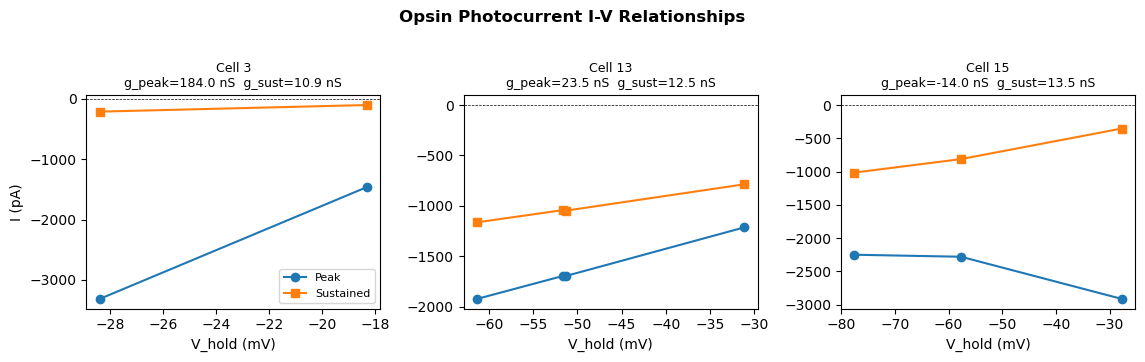

In [ ]:
(
    PlotGrid(vc_fits_df, height=3.5, aspect=1.1,
             suptitle='Opsin Photocurrent I-V Relationships')
    .map(_make_plot_iv_curve(vc_cond))
    .set_axis_labels('V_hold (mV)', 'I (pA)')
    .add_legend()
    .tight_layout()
    .show()
    .savefigs(figures_dir, 'vclamp_iv_curves')
)


## Current-Clamp Characterization of Opsin-Positive Cells to Tonic Light Pulses

Recordings are repeated in current-clamp (I-Clamp) mode to observe the suprathreshold spiking response to sustained optogenetic activation. Multiple files per cell are concatenated along the epoch dimension so that trial-to-trial variability in firing pattern can be assessed.


In [19]:
ic_files_df = extract_protocol_files(opsin_cells, TONIC_PROTOCOLS, clamp_mode='I-Clamp')

# Pipeline: load → format (per file)
ic_files_df = pipe_columns(ic_files_df, [
    ['fpath', lambda fp: format_blue_tonic_led(load_abf(fp)), 'rec'],
], errors='warn')
ic_files_df = ic_files_df.dropna(subset=['rec'])

# Group by cell and concat epochs
ic_recs_df = pipe_groupby_reduce(ic_files_df, 'cell_idx', [
    ['rec', _concat_epochs, 'rec'],
])

# Keep only epochs from the most common led_power level
ic_recs_df = apply_to_columns(ic_recs_df, 'rec', select_mode, 'led_power')

print(f"Loaded I-Clamp tonic recordings for {len(ic_recs_df)} cells")
ic_recs_df

Loaded I-Clamp tonic recordings for 3 cells


,subject,slice,cell,protocol,fpath,rec
cell_idx,,,,,,
3,DH46,Slice1,Cell2,Left_BlueLED_Tonic_IC,D:BetaGamma\project\invitro\v1\DH46\Slice1\Cel...,[[[<xarray.DataArray ()> Size: 8B\narray(-77.1...
13,DH55,Slice1,Cell3,Left_BlueLED_Tonic_IC,NaN,[[[<xarray.DataArray ()> Size: 8B\narray(-64.3...
15,DH56,Slice1,Cell1,Left_BlueLED_Tonic_IC,D:BetaGamma\project\invitro\v1\DH56\Slice1\Cel...,[[[<xarray.DataArray ()> Size: 8B\narray(-72.4...


### Plot I-Clamp Tonic LED Responses

The voltage channel is selected with `_prep_ic_voltage` and windowed around the LED pulse (50 ms pre-stimulus to 100 ms post-stimulus end). `stacked_lines` overlays all epochs as vertically offset traces so the consistency of the spiking response across trials is immediately visible. A vertical reference line marks LED onset.


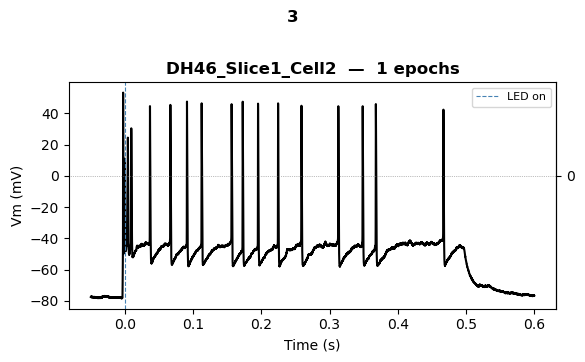

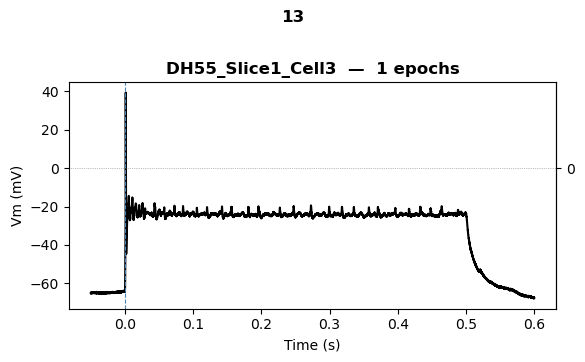

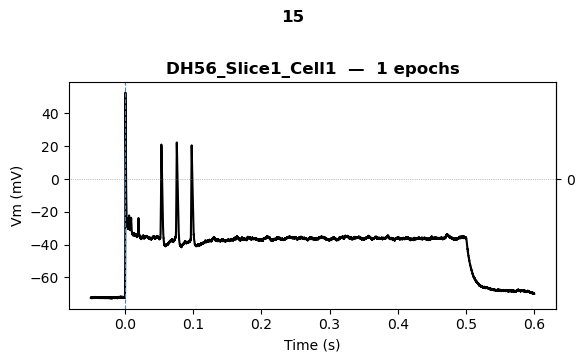

In [ ]:
ic_plot_df = apply_to_columns(ic_recs_df, 'rec', _prep_ic_voltage, result_cols='rec_v')
ic_plot_df = ic_plot_df.dropna(subset=['rec_v'])

(
    PlotGrid(ic_plot_df, fig='cell_idx', height=3.5, aspect=1.7, sharex=True, errors='warn')
    .map(_plot_ic_tonic)
    .refline(x=0, color='steelblue', lw=0.8, ls='--', label='LED on')
    .set_axis_labels('Time (s)', 'Vm (mV)')
    .add_legend()
    .tight_layout()
    .show()
    .savefigs(figures_dir, 'iclamp_tonic_led')
)


## Analyze Focal Optogenetic Stimulation

Spatial selectivity of the opsin response is assessed by sequentially illuminating discrete regions of the cell using a spatial light modulator or DMD pattern projector. Each pattern image is loaded from `imgs_path`. The ABF recording contains one epoch per pattern (plus a blank); `format_focal_stimulation` maps each epoch to the corresponding spatial pattern and attaches x/y coordinates so the response can be displayed as a spatial map. A fallback (I-Clamp preferred, then any clamp mode) ensures cells without I-Clamp focal recordings are still included.


In [22]:
# Load stimulation patterns
patterns = load_images(imgs_path, insert_blank=True)
n_patterns = len(patterns)
print(f"Loaded {n_patterns} patterns")
print(f"Processing {len(opsin_cells)} opsin-positive cells")

# Extract focal stimulation files
focal_files_df = extract_protocol_files(opsin_cells, FOCAL_PROTO_NAMES, clamp_mode='I-Clamp')

focal_files_df = pipe_columns(focal_files_df, [
    ['fpath',
     lambda fp: _load_and_format_focal(fp, patterns, n_patterns, patt_px_per_um),
     'rec'],
], errors='warn')
focal_files_df = focal_files_df.dropna(subset=['rec'])

# Keep last valid recording per cell (matches original behaviour)
focal_recs_df = focal_files_df.groupby('cell_idx').last().reset_index().set_index('cell_idx')
print(f"Collected focal stimulation recordings for {len(focal_recs_df)} cells")


Loaded 50 patterns
Processing 3 opsin-positive cells


C:\Users\dbh60\Documents\mimo\mimo2\mimo_pack\util\dataframe.py:59: UserWarning: Row 4, step producing ['rec']: n_epochs (8) <= n_patterns (50)
  warnings.warn(f"Row {idx}{label}: {exc}")


Collected focal stimulation recordings for 2 cells


### Evoked response maps

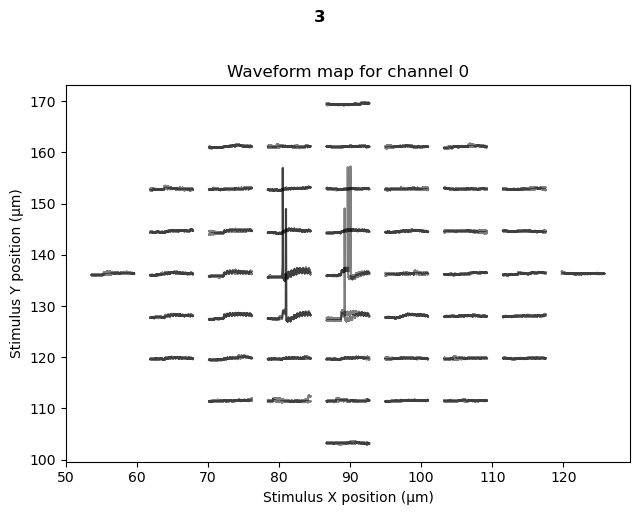

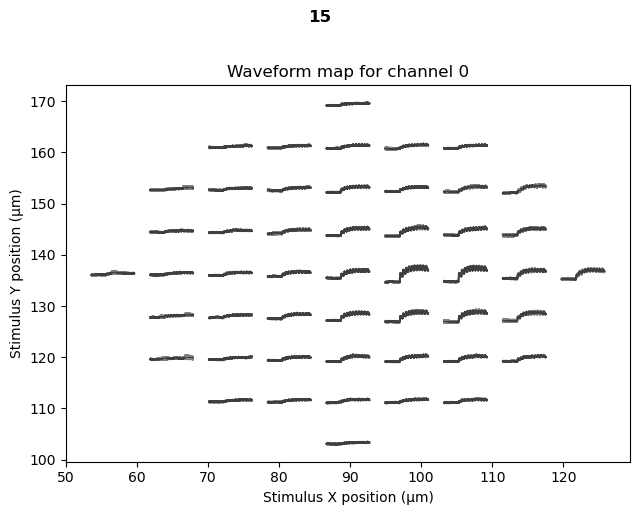

In [ ]:
(
    PlotGrid(
        focal_recs_df, fig='cell_idx', height=5, aspect=1.3,
        title_fn=lambda r: f"Cell {r.name} — {r['subject']} / {r['slice']} / {r['cell']}  [{r['protocol']}]",
        errors='warn',
    )
    .map(lambda row, ax: focal_stim_map(row['rec'], ax=ax, window=[-0.05, 0.1], x_scale=0.002))
    .tight_layout()
    .show()
    .savefigs(figures_dir, 'focal_stim_maps')
)


## Export Results

Save all processed DataArrays to disk. This section is optional during exploratory runs — skip it if you only need the plots above.

In [24]:
# Saves as NetCDF4 (.nc) files, one per cell.
# Filename pattern: {subject}_{slice}_{cell}_{label}.nc
# Reload with: xr.open_dataarray(path, engine='netcdf4')

# Prepare IVIC data for export
ivic_rows = [
    {'cell_idx': idx, 'rec': da}
    for idx, da in cell_class_widget.ivic_data.items()
    if idx in opsin_cells.index
]
ivic_df = pd.DataFrame(ivic_rows).set_index('cell_idx')
ivic_save_df = ivic_df.join(opsin_cells[['subject', 'slice', 'cell']])

# Save all DataArrays
for label, df, col in [
    ('iclamp_ivic_rec',    ivic_save_df,  'rec'),
    ('vclamp_tonic_rec',   vc_fits_df,    'rec'),
    ('iclamp_tonic_rec',   ic_recs_df,    'rec'),
    ('focal_stim_rec',     focal_recs_df, 'rec'),
]:
    paths = save_dataarray_df(df, col, save_dir,
                              name_cols=['subject', 'slice', 'cell'],
                              label=label)
    for p in paths:
        print(f"Saved: {p}")
    print()


Saved: D:BetaGamma\project\invitro\v1\processed\DH46_Slice1_Cell2_iclamp_ivic_rec.nc
Saved: D:BetaGamma\project\invitro\v1\processed\DH55_Slice1_Cell3_iclamp_ivic_rec.nc
Saved: D:BetaGamma\project\invitro\v1\processed\DH56_Slice1_Cell1_iclamp_ivic_rec.nc

Saved: D:BetaGamma\project\invitro\v1\processed\DH46_Slice1_Cell2_vclamp_tonic_rec.nc
Saved: D:BetaGamma\project\invitro\v1\processed\DH55_Slice1_Cell3_vclamp_tonic_rec.nc
Saved: D:BetaGamma\project\invitro\v1\processed\DH56_Slice1_Cell1_vclamp_tonic_rec.nc

Saved: D:BetaGamma\project\invitro\v1\processed\DH46_Slice1_Cell2_iclamp_tonic_rec.nc
Saved: D:BetaGamma\project\invitro\v1\processed\DH55_Slice1_Cell3_iclamp_tonic_rec.nc
Saved: D:BetaGamma\project\invitro\v1\processed\DH56_Slice1_Cell1_iclamp_tonic_rec.nc

Saved: D:BetaGamma\project\invitro\v1\processed\DH46_Slice1_Cell2_focal_stim_rec.nc
Saved: D:BetaGamma\project\invitro\v1\processed\DH56_Slice1_Cell1_focal_stim_rec.nc



## Summary

This notebook demonstrated:
1. Automated loading and organization of in vitro experimental data
2. Classification of neurons (FSI / RS / LTS / Unknown) based on standard ephys criteria
3. Opsin classification via tonic blue LED response fitting
4. Voltage-clamp photocurrent I-V characterization (conductance, reversal potential)
5. Current-clamp tonic LED response visualization
6. Spatial mapping of responses to focal optogenetic stimulation

Key mimo_pack components used:
- `invitro_files_df()` — organize experimental files
- `CellClassificationWidget` — interactive ephys-based cell classification
  (wraps `format_ivic` + `extract_iv_properties`)
- `OpsinClassificationWidget` — interactive opsin classification
  (wraps `format_blue_tonic_led` + `fit_opsin_response`)
- `opsin_iv_conductance()` — chord conductance / reversal potential from V-Clamp fits
- `format_focal_stimulation()` — attach spatial coordinates to focal stimulation recordings
- `focal_stim_map()` — visualize spatial response maps
- `stacked_lines()` — plot trial-by-trial responses
- `PlotGrid` — multi-panel figure layout from DataFrames
- `pipe_columns` / `pipe_groupby_reduce` — row-wise DataFrame processing pipelines